# Rocket Science — Takeoff and Landing

Launching a booster and landing it are problems of control and of estimation. This notebook
follows three phases of powered flight near Earth. In each one an Extended Kalman Filter (EKF),
the Kalman filter for nonlinear models, estimates the state of the vehicle from a few noisy
sensors.

1. **Liftoff**: a vertical climb. The rocket burns propellant, so it gets lighter and
   accelerates harder until the tanks are empty.
2. **Guided ascent**: a climb in two dimensions, where the thrust is the control input
   $\mathbf{u}$.
3. **Powered descent and landing**: a booster that tilts, steers with its engine and lands
   upright on a pad.

The notebook **08 — Space Science** continues from orbit to the Moon and Mars.

In [1]:
%pip install numpy matplotlib astropy > /dev/null
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05
np.seterr(all="ignore")

from kalman.apps.astro.rocket import (RocketLiftoffModel, RocketAscentModel, RocketDescentModel)
from kalman.runtime.astro import R_EARTH, KM, GM_EARTH

Note: you may need to restart the kernel to use updated packages.


## Step 1 — Vertical Liftoff: The Rocket Equation in Flight

The state is $\mathbf{x}$ = [altitude, climb rate, mass]. The engine burns propellant at a fixed
rate and gives a constant thrust. As the rocket gets lighter, the same thrust accelerates it
more. When the tanks are empty the engine stops and the rocket coasts up to its **apogee**, the
highest point.

The vehicle is close to a Falcon 9: 549 t at liftoff, of which 411 t is first-stage propellant
burned at 2.6 t/s, with a thrust of 7.5 MN. That is 1.4 times the weight at liftoff.

A ground station measures the altitude only, with a noise of 50 m (standard deviation, the
argument `track_m`). The EKF estimates the climb rate, which nothing measures, and follows the
mass through the known burn rate.

The cell prints the main figures of the flight. **Max-Q** is the largest aerodynamic pressure
on the vehicle. The values are of the right order for a real launcher, although a real one does
not fly straight up: it turns toward the horizontal, which is Step 2.

{'burnout time [s]': 158.1, 'burnout speed [m/s]': 2421.62, 'apogee [km]': 419.85, 'max accel [g]': 4.56, 'max-Q [kPa]': 27.24, 'liftoff TWR': 1.4}


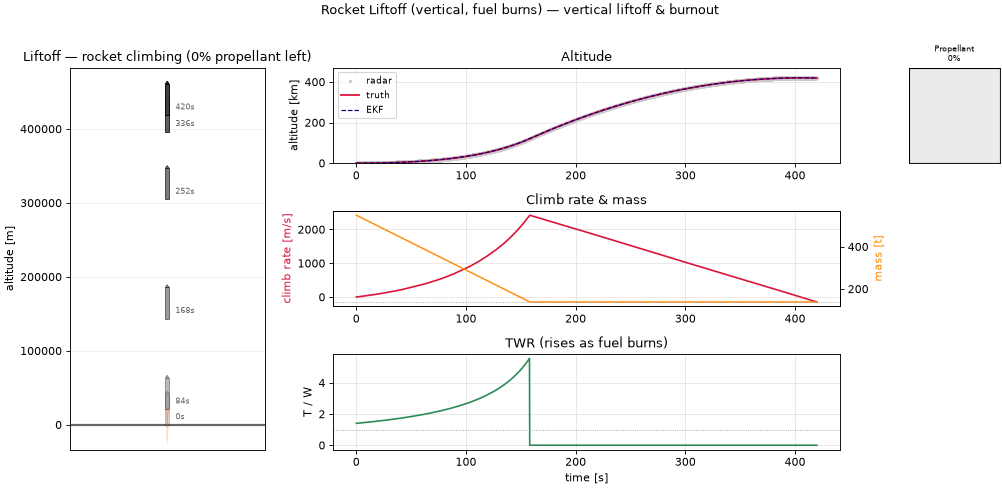

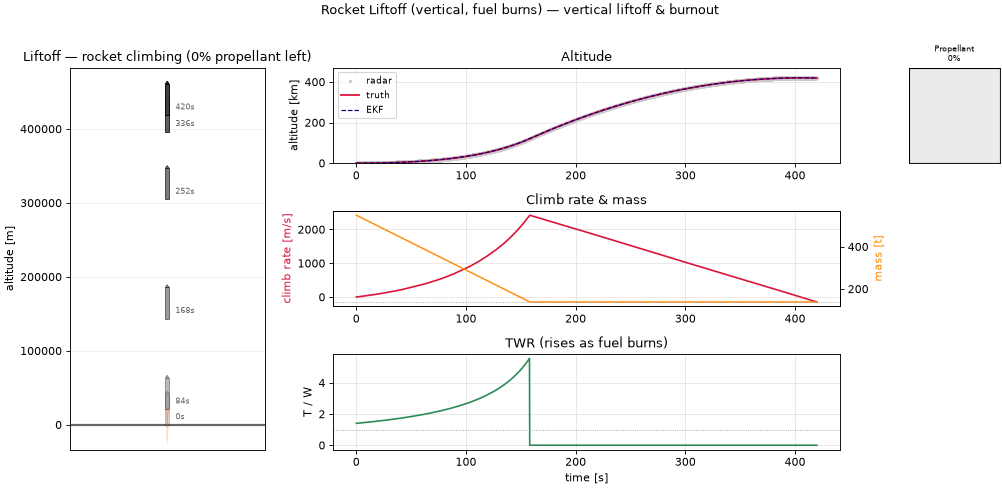

In [2]:
liftoff = RocketLiftoffModel("LIFTOFF",
                             m0=549_000.0,     # mass at liftoff [kg]
                             m_dry=138_000.0,  # mass once the first-stage propellant is gone [kg]
                             ve=2900.0,        # exhaust velocity [m/s]
                             mdot=2600.0,      # propellant flow [kg/s]; thrust = ve * mdot
                             drag_area=8.0,    # drag coefficient times cross-section [m^2]
                             length=70.0, width=3.7, fs=10.0,
                             track_m=50.0,     # altitude noise, standard deviation [m]
                             q_mass=0.0)       # the burn rate is known exactly
liftoff.initial_state([0.0, 0.0, liftoff.m0], P0=np.diag([50.0**2, 10.0**2, 50.0**2]))
flight = liftoff.sample(420.0)                # 7 min: liftoff, burnout, coast to apogee
est    = liftoff.filter(flight.zk)
print({k: round(v, 2) for k, v in liftoff.metrics(flight).items()})
liftoff.plot(est, sample=flight)

### Step 1b — Interactive Liftoff

The animation shows the rocket leaving the pad. The gauge shows the propellant left.

In [3]:
liftoff.plot(est, sample=flight, interactive=True)

## Step 2 — Guided Ascent: Thrust as a Control Input

Reaching orbit means moving sideways fast enough, not just going up. The rocket leaves the pad
almost vertically and then tips over steadily toward the horizontal. This manoeuvre is called a
**gravity turn**.

The state is the position and velocity in a plane, in axes fixed at the centre of the Earth. The
pad sits on the first axis, so at liftoff the first axis points up and the second points
downrange. The control input $\mathbf{u}$ is the acceleration given by the thrust, along the
same two axes.

Here the thrust acceleration is constant at 19.4 m/s², about 2 g, for 8 minutes. The pitch angle
of the thrust falls from 89° to −22° relative to the horizon of the pad. It ends below that
horizon because the Earth curves away: after 1600 km the local horizontal has dropped by 15°.
This program was chosen so that the rocket arrives at an altitude of about 250 km, flying
horizontally at the speed of a circular orbit.

A radar measures the position with a noise of 1 km (`track_km`). The EKF is given the same
$\mathbf{u}$ as the rocket and estimates position and velocity.

In [4]:
from kalman.runtime.astro import LU

# The model works in Mm (1000 km) and ks (1000 s): velocities are then in km/s
# and accelerations in m/s^2.
ascent = RocketAscentModel(dt_s=2.0, track_km=1.0)
N = 240                                       # 240 steps of 2 s = 8 min of powered flight
accel = 19.4                                  # thrust acceleration [m/s^2]
uk = np.zeros((N, 2))
for i in range(N):
    frac  = i / (N - 1)
    pitch = np.deg2rad(89.0 - 111.0 * frac ** 0.57)    # thrust angle above the pad's horizon
    uk[i] = [accel * np.sin(pitch), accel * np.cos(pitch)]   # [up, downrange] at the pad

ascent.initial_state(np.array([[R_EARTH], [0], [0], [0]]),
                     P0=np.diag([(1*KM)**2, (1*KM)**2, 0.01**2, 0.01**2]))
asc = ascent.sample(N / ascent.fs, uk=uk)
est = ascent.filter(asc.zk, uk)

# Where the rocket ends up
xf      = np.asarray(asc.xk)[-1]
r       = np.hypot(xf[0], xf[1])                       # distance from the Earth's centre [Mm]
alt_km  = (r - R_EARTH) * LU / 1e3
down_km = xf[1] * LU / 1e3
speed   = np.hypot(xf[2], xf[3])                       # [km/s]
climb   = (xf[0] * xf[2] + xf[1] * xf[3]) / r          # vertical part of the velocity [km/s]
v_circ  = np.sqrt(GM_EARTH / r)                        # speed of a circular orbit here [km/s]
print(f"insertion: altitude {alt_km:5.0f} km   downrange {down_km:5.0f} km   "
      f"speed {speed:4.2f} km/s ({speed/v_circ:4.0%} of orbital)   climb rate {climb:+5.2f} km/s")

insertion: altitude   243 km   downrange  1620 km   speed 7.75 km/s (100% of orbital)   climb rate -0.03 km/s


### Step 2b — Interactive Ascent

The rocket tips over along its path. The round dial is an artificial horizon and shows the tilt.
The gauge shows the speed as a fraction of orbital speed.

In [5]:
ascent.plot(est, sample=asc, interactive=True)

## Step 3 — Powered Descent and Landing: The Booster That Steers Itself

The booster is now a rigid body 40 m long that can tilt. Its engine can swivel by a small angle
$\delta$, the **gimbal** angle, which turns the booster. The state is

$$\mathbf{x} = [p_x,\; p_y,\; v_x,\; v_y,\; \theta,\; \omega,\; m]$$

with $p_x$ the horizontal distance from the pad (cross-range), $p_y$ the altitude, $\theta$ the
tilt from vertical, $\omega$ the tilt rate and $m$ the mass.

An autopilot inside the model flies the booster with three feedback loops:

- The throttle holds a descent speed of 55 m/s, then brakes so as to reach the pad slowly.
- The booster leans toward the pad to cancel the cross-range distance and drift.
- The gimbal turns the booster to that lean angle and brings it upright for touchdown.

The vehicle is the size of a Falcon 9 first stage: 22 t empty, 8 t of landing propellant and one
845 kN engine. It starts 2000 m up and 350 m to the side of the pad, falling at 60 m/s and
drifting.

Sensors measure $p_x$, $p_y$ and $\theta$, with a position noise of 15 m (standard deviation).
The EKF estimates the velocities and the tilt rate, which no sensor measures.

{'touchdown miss [m]': 1.36, 'touchdown speed [m/s]': 3.46, 'final tilt [deg]': 1.35, 'ignition time [s]': 0.0, 'ignition altitude [m]': 2000.0, 'propellant burned [kg]': 4282.68}


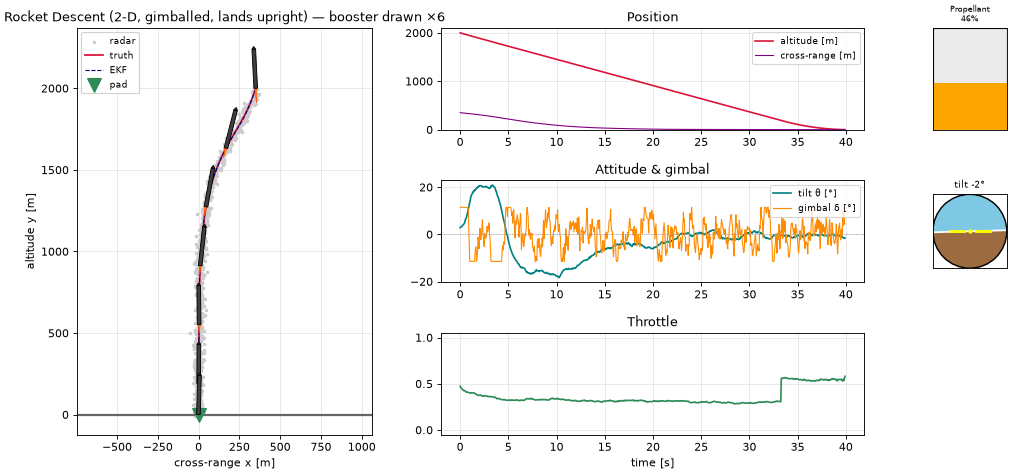

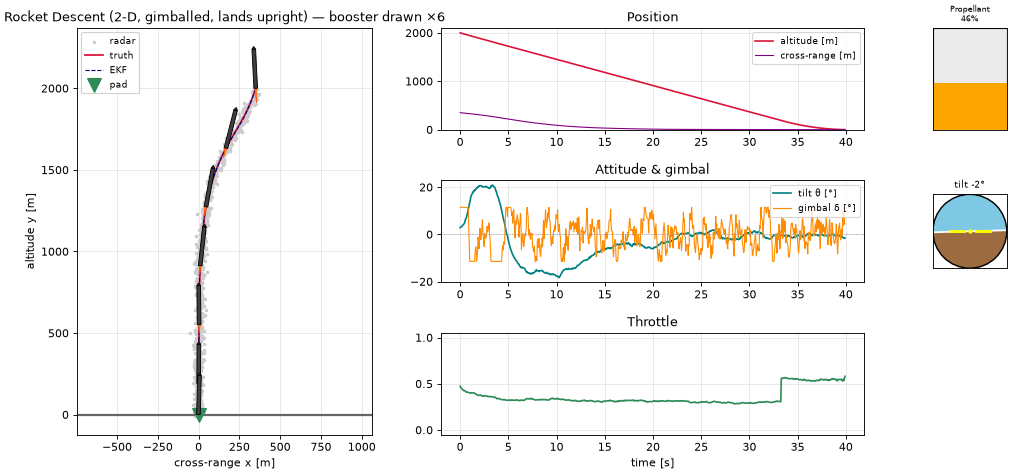

In [6]:
booster = dict(m0=30_000.0,          # mass at the start of the descent [kg]
               m_dry=22_000.0,       # mass without propellant [kg]
               thrust_max=845e3,     # full thrust [N]
               drag_area=10.0)       # drag coefficient times cross-section [m^2]
descent = RocketDescentModel(fs=20.0, **booster)
x0 = np.array([350.0, 2000.0,   # cross-range and altitude [m]
               -20.0, -60.0,    # horizontal and vertical velocity [m/s]
               0.05, 0.0,       # tilt [rad] and tilt rate [rad/s]
               descent.m0])     # mass [kg]
descent.initial_state(x0)
land = descent.sample(70.0)
est  = descent.filter(land.zk)
print({k: round(v, 2) for k, v in descent.metrics(land).items()})
descent.plot(est, sample=land)

### Step 3b — Interactive Descent

Press play or move the slider to watch the booster land. The flame grows with the throttle.

In [7]:
descent.plot(est, sample=land, interactive=True)

### Step 3c — The Control Input: Throttle and Gimbal

So far the autopilot was hidden inside the model. With `control=True` the two actuators become an
explicit control input, $\mathbf{u}$ = [throttle between 0 and 1, gimbal angle $\delta$ in rad].

`autopilot()` computes the sequence of commands `uk` for the whole descent. We fly it with
`sample(uk=uk)` and give the same commands to the EKF.

The two panels show what the autopilot asks of the engine: how hard to push, and which way to
swivel.

{'touchdown miss [m]': 0.02, 'touchdown speed [m/s]': 3.27, 'final tilt [deg]': 0.0, 'ignition time [s]': 0.0, 'ignition altitude [m]': 2000.0, 'propellant burned [kg]': 4287.72}


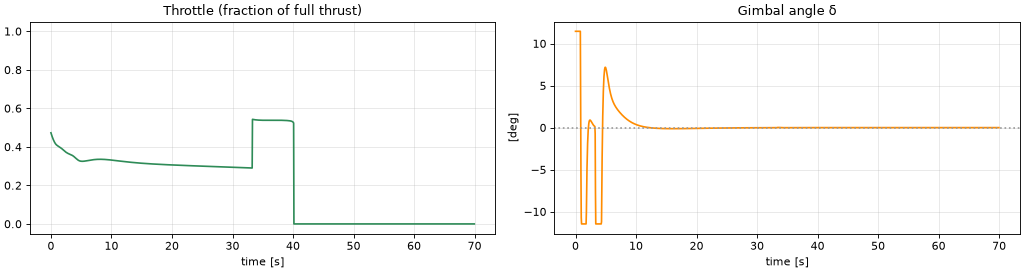

In [8]:
ctl = RocketDescentModel(fs=20.0, control=True, **booster)
N = int(70 * ctl.fs)
uk, _ = ctl.autopilot(x0, N)                           # commands for every step
ctl.initial_state(x0)
land2 = ctl.sample(N / ctl.fs, uk=uk, process_noise=False)   # no disturbances
est2  = ctl.filter(land2.zk, uk)

t = np.arange(len(uk)) / ctl.fs
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))

ax[0].plot(t, uk[:, 0], color="seagreen")
ax[0].set_ylim(-0.05, 1.05)
ax[0].set_title("Throttle (fraction of full thrust)")
ax[0].set_xlabel("time [s]")
ax[0].grid(alpha=0.3)

ax[1].plot(t, np.degrees(uk[:, 1]), color="darkorange")
ax[1].axhline(0, color="0.6", ls=":")
ax[1].set_title("Gimbal angle δ")
ax[1].set_xlabel("time [s]")
ax[1].set_ylabel("[deg]")
ax[1].grid(alpha=0.3)

fig.tight_layout()
print({k: round(v, 2) for k, v in ctl.metrics(land2).items()})

## Extensions

- Make the landing harder: start further from the pad, with more tilt, or with more drag. Check
  that the booster still lands upright.
- Fly the booster yourself: give your own `uk = [throttle, gimbal]` to a `control=True` model
  instead of calling `autopilot()`.
- Change the sensor noise (`track_m`, `track_th`) or the process noise (`q_*`) and see how the
  EKF trades smoothness against speed of response.
- Continue with **08 — Space Science**, which flies to the Moon and on to Mars.